# Rush 4 – Segmentation des utilisateurs Instagram

**Objectif :** regrouper les 200 000 volontaires en familles d'usage, puis décrire ces familles avec les indicateurs de bien-être.

**Règles éthiques suivies dans ce notebook :**
- aucune ligne individuelle n'est affichée, seulement des résultats agrégés ;
- les données de santé servent à **décrire** les familles, jamais à les **construire** ;
- les noms des familles décrivent des comportements, pas des états de santé ;
- les démonstrations utilisent uniquement des profils fictifs.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

RANDOM_STATE = 42
CHEMIN = "data/instagram_users_lifestyleSafe.csv"
CHEMIN_BRUT = "data/instagram_usage_lifestyleSafe.csv"

In [31]:
df = pd.read_csv(CHEMIN)
print(df.shape)

(200000, 58)


## 1. Choix du fichier

In [33]:
brut = pd.read_csv(CHEMIN_BRUT)
a = df.sort_values("user_id").reset_index(drop=True)
b = brut.sort_values("user_id").reset_index(drop=True)
print("Mêmes utilisateurs dans les deux fichiers :", a["user_id"].equals(b["user_id"]))

differences = pd.Series({col: (a[col] != b[col]).sum() for col in a.columns})
differences[differences > 0].sort_values(ascending=False)

Mêmes utilisateurs dans les deux fichiers : True


account_creation_year    31772
employment_status        18913
weekly_work_hours        18912
relationship_status       6623
has_children              5329
education_level           1203
dtype: int64

In [34]:
def incoherences_mineurs(table):
    mineur = table["age"] < 18
    return pd.Series({
        "mineurs avec un emploi": (mineur & ~table["employment_status"].isin(["Student", "Not employed", "Unemployed"])).sum(),
        "mineurs avec des heures de travail": (mineur & (table["weekly_work_hours"] > 0)).sum(),
        "mineurs mariés, divorcés ou veufs": (mineur & table["relationship_status"].isin(["Married", "Divorced", "Widowed"])).sum(),
        "mineurs avec des enfants": (mineur & (table["has_children"] == "Yes")).sum(),
        "mineurs titulaires d'un diplôme du supérieur": (mineur & table["education_level"].isin(["Bachelor’s", "Master’s", "PhD"])).sum(),
    })

pd.DataFrame({"fichier brut (usage)": incoherences_mineurs(brut),
              "fichier corrigé (users)": incoherences_mineurs(df)})

,fichier brut (usage),fichier corrigé (users)
mineurs avec un emploi,12847,0
mineurs avec des heures de travail,18912,0
"mineurs mariés, divorcés ou veufs",6623,0
mineurs avec des enfants,5329,0
mineurs titulaires d'un diplôme du supérieur,9403,8828


In [35]:
def controle_dates(table):
    annee_connexion = pd.to_datetime(table["last_login_date"]).dt.year
    age_creation = table["account_creation_year"] - (annee_connexion - table["age"])
    return pd.Series({
        "compte créé après la dernière connexion": (table["account_creation_year"] > annee_connexion).sum(),
        "compte créé avant 13 ans": (age_creation < 13).sum(),
    })

resultat = pd.DataFrame({"fichier brut (usage)": controle_dates(brut),
                         "fichier corrigé (users)": controle_dates(df)})
del brut, a, b
resultat

,fichier brut (usage),fichier corrigé (users)
compte créé après la dernière connexion,0,3724
compte créé avant 13 ans,27989,0


**Décision : nous travaillons avec le fichier `users`.** Les deux fichiers contiennent les mêmes 200 000 utilisateurs, et seules 6 colonnes diffèrent. Le fichier `users` corrige les incohérences du fichier brut : plus aucun mineur n'a d'emploi, de conjoint ou d'enfant, et plus aucun compte n'a été créé avant 13 ans.

**Ce qui reste imparfait :** 8 828 mineurs ont encore un diplôme du supérieur, et 3 724 comptes ont été créés après leur dernière connexion. Ces colonnes ne servent pas à construire les familles, donc ces défauts ne faussent pas la segmentation.

## 2. Contrôle qualité

In [36]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Utilisateurs en double :", df["user_id"].duplicated().sum())
print("Clics pub supérieurs aux pubs vues :", (df["ads_clicked_per_day"] > df["ads_viewed_per_day"]).sum())

temps_sections = df[["time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day", "time_on_reels_per_day"]].sum(axis=1)
print("Écart moyen entre temps total et somme des sections (min) :", round((df["daily_active_minutes_instagram"] - temps_sections).abs().mean(), 1))

Valeurs manquantes : 0
Utilisateurs en double : 0
Clics pub supérieurs aux pubs vues : 628
Écart moyen entre temps total et somme des sections (min) : 33.9


In [37]:
annee_connexion = pd.to_datetime(df["last_login_date"]).dt.year
age_creation = df["account_creation_year"] - (annee_connexion - df["age"])

coree = (df["country"] == "South Korea") & (age_creation < 14)
australie = (df["country"] == "Australia") & (age_creation < 16) & (df["account_creation_year"] >= 2026)
a_retirer = coree | australie

print("Corée du Sud, compte créé avant 14 ans :", coree.sum())
print("Australie, compte créé avant 16 ans en 2026 :", australie.sum())
print("Australiens ayant aujourd'hui moins de 16 ans :", ((df["country"] == "Australia") & (df["age"] < 16)).sum())

df = df[~a_retirer].reset_index(drop=True)
print("Profils retirés :", a_retirer.sum(), "| Utilisateurs restants :", len(df))

Corée du Sud, compte créé avant 14 ans : 14
Australie, compte créé avant 16 ans en 2026 : 213
Australiens ayant aujourd'hui moins de 16 ans : 671
Profils retirés : 227 | Utilisateurs restants : 199773


**Résultats.** Le fichier ne contient ni valeur manquante ni doublon. Deux incohérences propres à la réplique synthétique subsistent : 628 utilisateurs cliquent sur plus de publicités qu'ils n'en voient, et le temps total quotidien diffère en moyenne de 34 minutes de la somme des temps par section.

**Âge minimal par pays.** Nous retirons par précaution 227 profils (0,11 % du fichier) : 14 Sud-Coréens ayant créé leur compte avant 14 ans, et 213 Australiens l'ayant créé avant 16 ans depuis l'entrée en vigueur de la loi australienne (10 décembre 2025). Il s'agit de mineurs, dans une étude sur la santé mentale : le principe de minimisation du RGPD justifie de ne pas traiter leurs données. **L'analyse porte donc sur 199 773 utilisateurs.**

**Point d'alerte.** 671 Australiens ont aujourd'hui moins de 16 ans : ils devront être exclus de tout ciblage réel. **Limite :** le fichier ne donne que l'année de création du compte, donc l'âge à la création est estimé à un an près.

## 3. Choix des colonnes

Nous appliquons trois filtres successifs : **la loi** (RGPD), **la redondance** (une colonne qui répète le temps passé n'apporte rien), puis **le style d'usage** (des ratios qui décrivent *comment* on utilise Instagram, et non *combien*).

### Filtre 1 : le RGPD

In [38]:
EXCLUES_RGPD = {
    "santé (article 9 du RGPD)": ["exercise_hours_per_week", "sleep_hours_per_night", "diet_quality", "smoking",
        "alcohol_frequency", "perceived_stress_score", "self_reported_happiness", "body_mass_index",
        "blood_pressure_systolic", "blood_pressure_diastolic", "daily_steps_count"],
    "vie privée (hors finalité)": ["income_level", "employment_status", "education_level", "relationship_status",
        "has_children", "weekly_work_hours", "hobbies_count", "social_events_per_month", "books_read_per_year",
        "volunteer_hours_per_month", "travel_frequency_per_year"],
    "profil sensible (risque de discrimination)": ["age", "gender", "country", "urban_rural"],
}

for categorie, colonnes in EXCLUES_RGPD.items():
    print(f"{categorie} : {len(colonnes)} colonnes")
print("Total exclu de la construction des familles :", sum(len(c) for c in EXCLUES_RGPD.values()), "colonnes sur", df.shape[1])

santé (article 9 du RGPD) : 11 colonnes
vie privée (hors finalité) : 11 colonnes
profil sensible (risque de discrimination) : 4 colonnes
Total exclu de la construction des familles : 26 colonnes sur 58


**Pourquoi le consentement ne suffit pas.** Les volontaires ont accepté une étude sur le bien-être, pas un profilage publicitaire. Le RGPD exige un consentement spécifique à chaque finalité. Les données de santé (article 9) servent donc uniquement à décrire les familles. Les données de vie privée sont hors sujet. L'âge, le genre et le pays servent seulement à vérifier qu'aucune famille ne cible un groupe protégé.

### Filtre 2 : la redondance

In [39]:
CANDIDATES = ["daily_active_minutes_instagram", "sessions_per_day", "average_session_length_minutes",
    "posts_created_per_week", "reels_watched_per_day", "stories_viewed_per_day", "likes_given_per_day",
    "comments_written_per_day", "dms_sent_per_week", "dms_received_per_week", "ads_viewed_per_day",
    "ads_clicked_per_day", "time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day",
    "time_on_reels_per_day", "followers_count", "following_count", "notification_response_rate",
    "linked_accounts_count", "uses_premium_features", "user_engagement_score"]

candidats = df[CANDIDATES].replace({"Yes": 1, "No": 0})
filtre2 = pd.DataFrame({
    "nunique": candidats.nunique(),
    "corr_temps_passe": candidats.corrwith(df["daily_active_minutes_instagram"]),
    "corr_stress": candidats.corrwith(df["perceived_stress_score"]),
    "corr_bonheur": candidats.corrwith(df["self_reported_happiness"]),
}).round(2)
filtre2.sort_values("corr_temps_passe", ascending=False)

,nunique,corr_temps_passe,corr_stress,corr_bonheur
daily_active_minutes_instagram,531,1.00,0.83,-0.37
likes_given_per_day,306,0.98,0.82,-0.37
time_on_feed_per_day,305,0.97,0.81,-0.36
stories_viewed_per_day,138,0.95,0.81,-0.35
comments_written_per_day,81,0.94,0.79,-0.35
time_on_reels_per_day,203,0.93,0.78,-0.35
dms_received_per_week,89,0.92,0.77,-0.35
dms_sent_per_week,81,0.90,0.75,-0.34
time_on_messages_per_day,124,0.90,0.75,-0.33
ads_viewed_per_day,51,0.89,0.75,-0.33


**Lecture.** 13 colonnes ont une corrélation supérieure à 0,7 avec le temps passé (likes, stories, temps sur le fil, messages, etc.) : elles répètent la même information sous une autre forme. Les followers, les notifications, les comptes liés et l'abonnement premium ne sont liés ni au temps ni au bien-être. Le `user_engagement_score` est exclu : c'est un score déjà calculé dont on ignore la formule (corrélation de −0,53 avec le temps passé).

**Conclusion :** le temps passé résume à lui seul l'intensité d'usage. Pour obtenir des familles utiles, il faut décrire le *style* d'usage, et non la quantité.

### Filtre 3 : le style d'usage

In [41]:
temps_total = df[["time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day", "time_on_reels_per_day"]].sum(axis=1)

df["part_reels"] = df["time_on_reels_per_day"] / temps_total
df["part_messages"] = df["time_on_messages_per_day"] / temps_total
df["part_explore"] = df["time_on_explore_per_day"] / temps_total
df["ratio_createur"] = (df["posts_created_per_week"] / 7 + df["comments_written_per_day"]) / (df["likes_given_per_day"] + df["stories_viewed_per_day"] + 1)
df["taux_clic_pub"] = df["ads_clicked_per_day"] / (df["ads_viewed_per_day"] + 1)
df["ratio_abonnes"] = df["followers_count"] / (df["following_count"] + 1)
df["sessions_par_heure"] = df["sessions_per_day"] / (df["daily_active_minutes_instagram"] / 60)

RATIOS = ["part_reels", "part_messages", "part_explore", "ratio_createur", "taux_clic_pub", "ratio_abonnes", "sessions_par_heure"]

filtre3 = pd.DataFrame({
    "corr_temps_passe": df[RATIOS].corrwith(df["daily_active_minutes_instagram"]),
    "corr_stress": df[RATIOS].corrwith(df["perceived_stress_score"]),
}).round(2)
filtre3

,corr_temps_passe,corr_stress
part_reels,0.02,0.01
part_messages,-0.05,-0.04
part_explore,-0.00,-0.00
ratio_createur,0.36,0.29
taux_clic_pub,0.06,0.05
ratio_abonnes,0.01,0.01
sessions_par_heure,-0.35,-0.28


In [42]:
for cible in ["perceived_stress_score", "self_reported_happiness"]:
    r2_temps = cross_val_score(LinearRegression(), df[["daily_active_minutes_instagram"]], df[cible], cv=5, scoring="r2").mean()
    r2_ratios = cross_val_score(LinearRegression(), df[["daily_active_minutes_instagram"] + RATIOS], df[cible], cv=5, scoring="r2").mean()
    print(f"{cible} : temps seul R² = {r2_temps:.3f} | temps + ratios R² = {r2_ratios:.3f}")

perceived_stress_score : temps seul R² = 0.696 | temps + ratios R² = 0.697
self_reported_happiness : temps seul R² = 0.140 | temps + ratios R² = 0.143


**Lecture.** Le temps passé explique à lui seul 69,6 % des écarts de stress. Ajouter les 7 ratios ne fait gagner que 0,1 point. Le style d'usage n'est donc **pas** un facteur de stress dans ces données : c'est la quantité qui compte.

**Conséquence pour la segmentation.** Les familles construites sur le style décriront des **manières d'utiliser Instagram**, utiles pour adapter l'expérience. Elles ne permettront pas d'identifier les utilisateurs en souffrance : cette question relève du temps passé. Nous retirons `ratio_createur` et `sessions_par_heure`, trop liés au temps passé (corrélation de ±0,35), pour ne garder que des ratios de style « purs ».

## 4. Préparation des données

Chaque colonne a un rôle précis, et un seul :
- **STYLE** (5 ratios) : les seules colonnes qui **construisent** les familles ;
- **DÉCRIRE** (temps passé, stress, bonheur, sommeil) : utilisées **après coup**, pour décrire les familles ;
- **VÉRIFIER** (âge, genre, pays) : utilisées seulement pour contrôler qu'aucune famille ne cible un groupe protégé.

In [43]:
STYLE = ["part_reels", "part_messages", "part_explore", "taux_clic_pub", "ratio_abonnes"]
DECRIRE = ["daily_active_minutes_instagram", "perceived_stress_score", "self_reported_happiness", "sleep_hours_per_night"]
VERIFIER = ["age", "gender", "country"]

df[STYLE].describe().round(3)

,part_reels,part_messages,part_explore,taux_clic_pub,ratio_abonnes
count,199773.000,199773.000,199773.000,199773.000,199773.000
mean,0.255,0.150,0.169,0.234,0.901
std,0.044,0.034,0.043,0.146,0.518
min,0.125,0.059,0.059,0.000,0.389
25%,0.220,0.122,0.135,0.143,0.519
50%,0.255,0.150,0.168,0.216,0.717
75%,0.287,0.175,0.202,0.303,1.122
max,0.397,0.273,0.333,7.000,12.597


**Lecture.** Les trois parts de temps sont très regroupées, entre 0,06 et 0,40. En revanche, `taux_clic_pub` monte jusqu'à 7 et `ratio_abonnes` jusqu'à 12,6, alors que leur moyenne est inférieure à 1. Ces valeurs extrêmes attireraient K-means vers quelques profils isolés. Nous les **plafonnons** donc au 1er et au 99e centile, puis nous **standardisons** toutes les colonnes, pour qu'elles pèsent le même poids.

In [44]:
borne_basse = df[STYLE].quantile(0.01)
borne_haute = df[STYLE].quantile(0.99)
print("Valeurs plafonnées par colonne :")
print(((df[STYLE] < borne_basse) | (df[STYLE] > borne_haute)).sum())

style_plafonne = df[STYLE].clip(lower=borne_basse, upper=borne_haute, axis=1)
scaler = StandardScaler().fit(style_plafonne)
X = scaler.transform(style_plafonne)

pd.DataFrame(X, columns=STYLE).describe().loc[["mean", "std", "min", "max"]].round(2)

Valeurs plafonnées par colonne :
part_reels       2620
part_messages    3991
part_explore     3987
taux_clic_pub    1947
ratio_abonnes    3996
dtype: int64


,part_reels,part_messages,part_explore,taux_clic_pub,ratio_abonnes
mean,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.01,-1.91,-1.89,-1.74,-0.99
max,2.11,2.13,2.06,3.27,3.03


## 5. Choix du nombre de familles (K)

Nous testons K de 2 à 8 avec deux mesures : l'**inertie**, qui doit baisser nettement (méthode du coude), et la **silhouette**, qui doit être la plus haute possible. La silhouette est calculée sur un échantillon de 20 000 utilisateurs, pour limiter le temps de calcul.

In [45]:
echantillon = np.random.RandomState(RANDOM_STATE).choice(len(X), 20000, replace=False)
resultats = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    resultats.append({"K": k,
                      "inertie": round(km.inertia_),
                      "silhouette": round(silhouette_score(X[echantillon], km.labels_[echantillon]), 3)})
choix_k = pd.DataFrame(resultats).set_index("K")
choix_k

,inertie,silhouette
K,,
2,811261,0.183
3,694732,0.176
4,597151,0.193
5,533776,0.197
6,489750,0.180
7,464452,0.178
8,442281,0.166


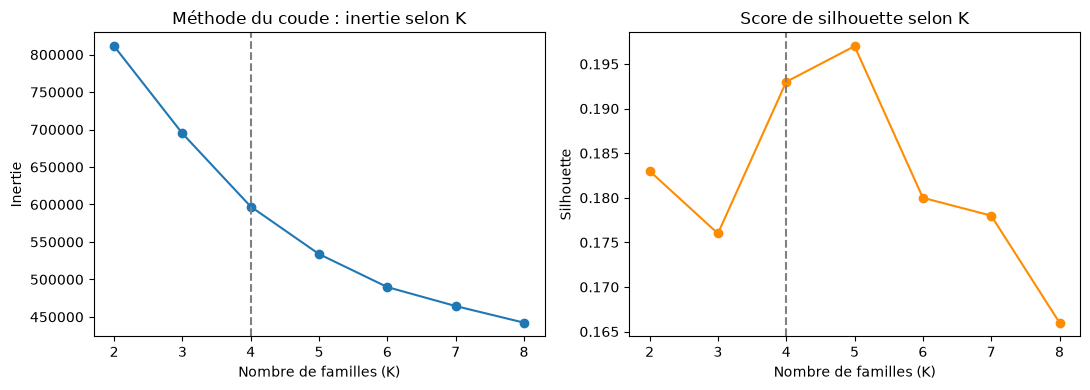

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(choix_k.index, choix_k["inertie"], marker="o")
axes[0].set_title("Méthode du coude : inertie selon K")
axes[0].set_xlabel("Nombre de familles (K)")
axes[0].set_ylabel("Inertie")
axes[1].plot(choix_k.index, choix_k["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Score de silhouette selon K")
axes[1].set_xlabel("Nombre de familles (K)")
axes[1].set_ylabel("Silhouette")
for ax in axes:
    ax.axvline(4, color="grey", linestyle="--")
plt.tight_layout()
plt.show()

**Décision : K = 4.** La silhouette remonte nettement à K = 4 (0,193, contre 0,176 à K = 3). K = 5 fait à peine mieux (0,197), mais ajoute une famille de plus, plus difficile à interpréter. Au-delà, la silhouette baisse et l'inertie ne diminue presque plus.

**Limite :** une silhouette proche de 0,2 signifie que les familles se chevauchent. Il s'agit de tendances d'usage, et non de groupes nettement séparés.

## 6. Modèle final et stabilité

Nous vérifions la stabilité en relançant K-means avec trois autres graines aléatoires. L'**ARI** compare deux découpages : 1 signifie qu'ils sont identiques, 0 qu'ils ne se ressemblent pas plus que le hasard.

In [48]:
K = 4
modele = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X)
df["famille"] = modele.labels_

for graine in [1, 7, 123]:
    autre = KMeans(n_clusters=K, random_state=graine, n_init=10).fit(X)
    print(f"Graine {graine} : ARI = {adjusted_rand_score(modele.labels_, autre.labels_):.3f}")

Graine 1 : ARI = 0.977
Graine 7 : ARI = 0.982
Graine 123 : ARI = 0.995


In [49]:
centres = pd.DataFrame(modele.cluster_centers_, columns=STYLE).round(2)
centres

,part_reels,part_messages,part_explore,taux_clic_pub,ratio_abonnes
0,0.89,-0.08,-0.87,-0.02,-0.35
1,0.01,0.02,-0.01,-0.00,1.93
2,-0.11,-0.86,0.90,0.04,-0.34
3,-0.88,0.94,0.07,-0.02,-0.34


In [50]:
TRAITS = {"part_reels": "Adeptes des Reels", "part_messages": "Messagers",
          "part_explore": "Explorateurs", "ratio_abonnes": "Comptes très suivis"}
NOMS = {i: TRAITS[centres.loc[i, list(TRAITS)].idxmax()] for i in centres.index}
print(NOMS)

df["nom_famille"] = df["famille"].map(NOMS)
(df["nom_famille"].value_counts(normalize=True) * 100).round(1)

{0: 'Adeptes des Reels', 1: 'Comptes très suivis', 2: 'Explorateurs', 3: 'Messagers'}


nom_famille
Adeptes des Reels      30.4
Messagers              27.3
Explorateurs           27.3
Comptes très suivis    15.0
Name: proportion, dtype: float64

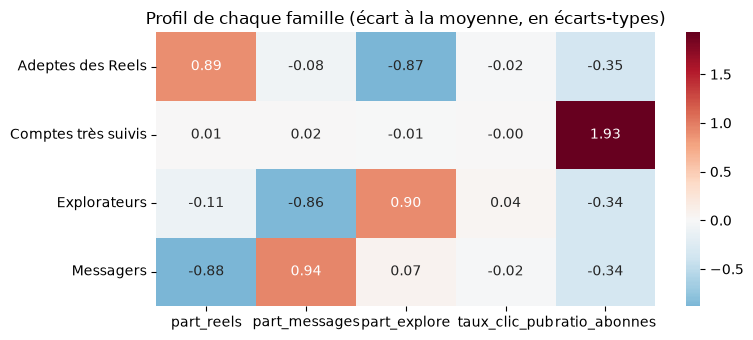

In [51]:
plt.figure(figsize=(8, 3.5))
sns.heatmap(centres.rename(index=NOMS), annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Profil de chaque famille (écart à la moyenne, en écarts-types)")
plt.tight_layout()
plt.show()

**Stabilité.** L'ARI dépasse 0,97 pour les trois graines : les familles ne dépendent pas du hasard de l'initialisation.

**Les 4 familles**, nommées automatiquement d'après leur trait le plus marqué :
- **Adeptes des Reels (30,4 %)** : beaucoup de Reels, peu d'Explorer ;
- **Explorateurs (27,3 %)** : beaucoup d'Explorer, peu de messages ;
- **Messagers (27,3 %)** : beaucoup de messages, peu de Reels ;
- **Comptes très suivis (15,0 %)** : bien plus d'abonnés que d'abonnements.

Le taux de clic publicitaire est identique dans les quatre familles (valeurs proches de 0) : il ne distingue personne.